# Run Analysis Notebook
This notebook is designed to analyze the performance of the train-delay compensation agent.
It uses `analyze_run.py` to load the results into Pandas for statistical analysis and visualization.

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from analyze_run import load_run_analysis
from pathlib import Path

# --- CONFIGURATION ---
# Point this to the run directory you want to analyze
RUN_PATH = "runs/20261110-144618-20476-system" 
# ---------------------

summary, rows, grades = load_run_analysis(RUN_PATH)
df = pd.DataFrame(rows)

print(f"Loaded {len(df)} requests from {RUN_PATH}")
df.head()

Loaded 36 requests from runs/20261110-144618-20476-system


,id,points,penalty,max,correct,extra,questions,limit,over,tools,model,usd,status,issues,seconds,grade_correct,grade_max,detailed_failures,wrong_no_claims
0,P001,1.0,0.0,1,1,0,1,3,0,6,9,0.00108,ok,[],17.65,1,1,[],NaN
1,P002,0.0,0.0,1,0,0,4,4,0,9,13,0.00172,ok,[P],25.02,0,1,[provenance],NaN
2,P003,1.0,0.0,1,1,0,1,2,0,4,9,0.00150,ok,[],20.73,1,1,[],NaN
3,P004,1.0,0.0,1,1,0,1,2,0,4,7,0.00144,ok,[],13.74,1,1,[],NaN
4,P005,1.0,0.0,1,1,0,3,4,0,7,11,0.00147,ok,[],21.42,1,1,[],NaN


## 1. High-Level Performance
Check the overall points and distribution of statuses.

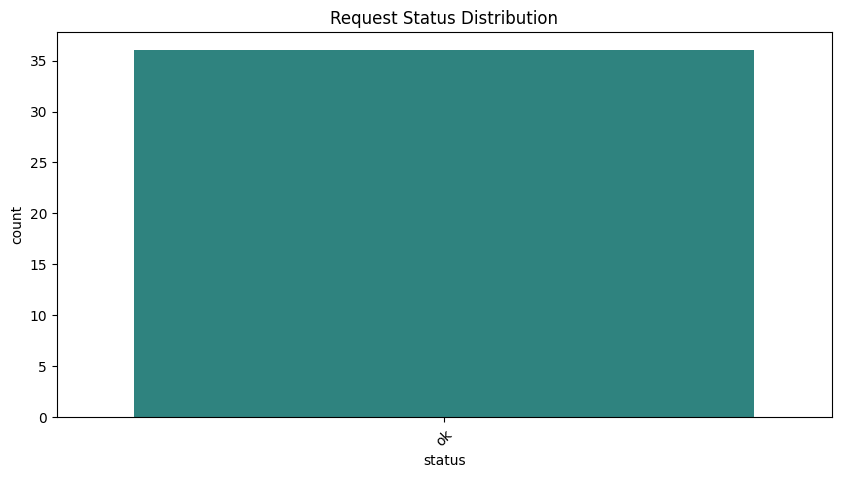

Overall Points: 20.25 / 36
Fully Right: 20 / 36


In [2]:
plt.figure(figsize=(10, 5))
sns.countplot(data=df, x='status', hue='status', palette='viridis', legend=False)
plt.title("Request Status Distribution")
plt.xticks(rotation=45)
plt.show()

print(f"Overall Points: {summary['totals'].get('points', 0)} / {summary['totals'].get('max', 0)}")
print(f"Fully Right: {summary.get('fully_right', 0)} / {len(df)}")

## 2. Failure Analysis
The most critical part: why is the agent failing? We'll analyze the `issues` provided by the runner.

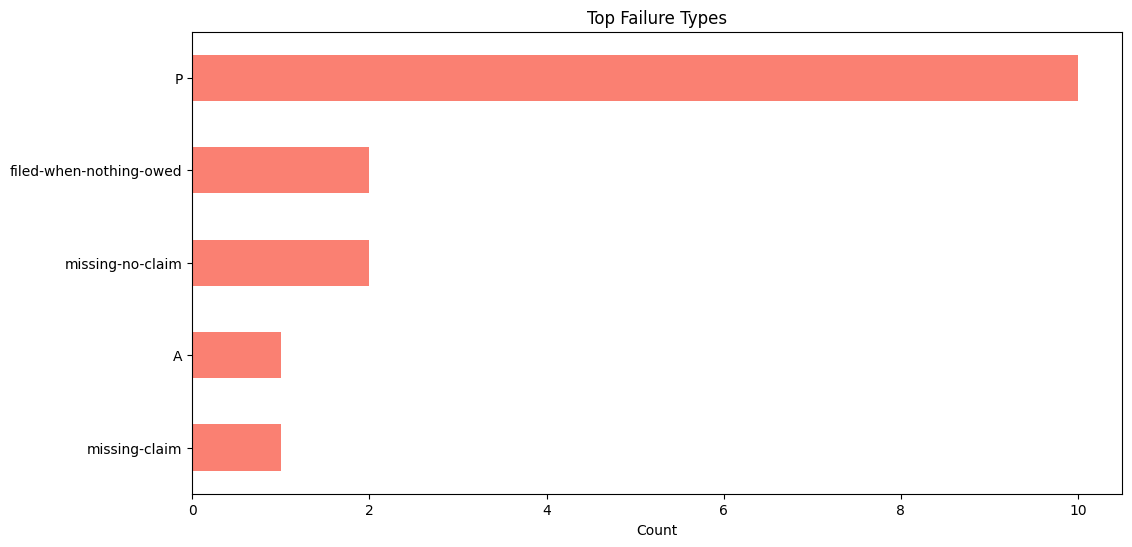

In [3]:
# Explode the issues list to count individual failure types
all_issues = [issue for sublist in df['issues'] for issue in sublist]
issue_counts = pd.Series(all_issues).value_counts()

plt.figure(figsize=(12, 6))
issue_counts.plot(kind='barh', color='salmon')
plt.title("Top Failure Types")
plt.xlabel("Count")
plt.gca().invert_yaxis()
plt.show()

## 3. Detailed Error Breakdown (A, T, P)
For cases that were filed but wrong, we look at Amount (A), Train (T), and Provenance (P).

In [4]:
# Filter for cases that attempted to file but were not fully right
failed_filings = df[(df['status'] == 'ok') & (df['fully_right'] == False)]

all_details = [item for sublist in failed_filings['detailed_failures'] for item in sublist]
detail_counts = pd.Series(all_details).value_counts()

plt.figure(figsize=(8, 4))
detail_counts.plot(kind='pie', autopct='%1.1f%%', startangle=140, colors=['#ff9999','#66b3ff','#99ff99'])
plt.title("Breakdown of Filing Errors (Amount, Train, Provenance)")
plt.ylabel("")
plt.show()

KeyError: 'fully_right'

## 4. Resource Usage vs Success
Do requests that take more model calls or time tend to be more successful?

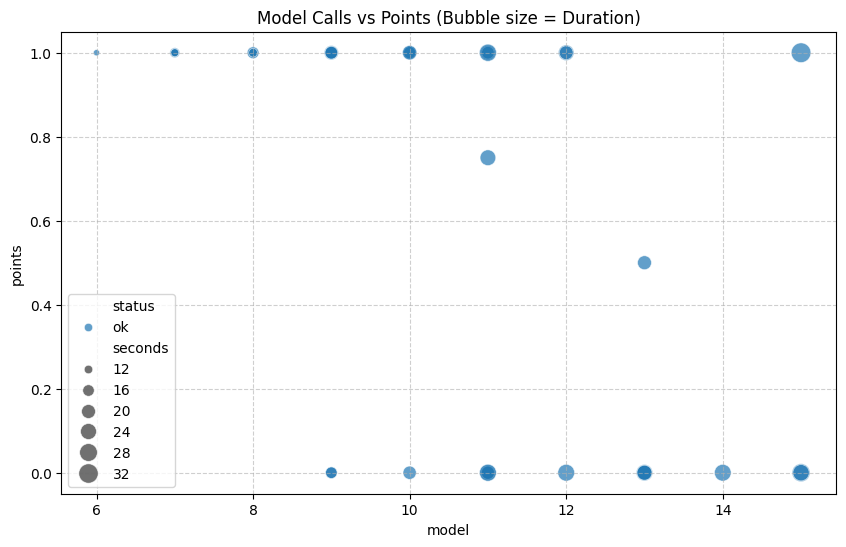

In [5]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='model', y='points', hue='status', size='seconds', sizes=(20, 200), alpha=0.7)
plt.title("Model Calls vs Points (Bubble size = Duration)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()